<img src="https://hilpisch.com/tpq_logo.png" alt="The Python Quants" width="35%" align="right" border="0"><br>

# Interview Prep &mdash; Lead Data Scientist

**FX Treasury &amp; Market Data Quant Team**

A Python-based preparation notebook with simulated market data.

&copy; Dr. Yves J. Hilpisch

<a href="https://tpq.io" target="_blank">https://tpq.io</a> | <a href="https://twitter.com/dyjh" target="_blank">@dyjh</a> | <a href="mailto:team@tpq.io">team@tpq.io</a>

## How to use this notebook

A self-contained preparation kit: each concept is explained in markdown, then **demonstrated in Python on simulated data**. Run cells top-to-bottom (fixed seed = reproducible).

| Part | Focus |
|---|---|
| **0** | Role mapping &mdash; what the team does |
| **1** | FX domain fundamentals: pairs, pips, spread, settlement |
| **2** | Statistical toolkit: VaR, CVaR, volatility |
| **3** | Time series: stationarity, autocorrelation, EWMA/GARCH |
| **4** | Machine learning: features, honest backtesting, overfitting |
| **5** | Risk model validation: Kupiec test, hit ratios |
| **6** | Market-data engineering: ticks, timestamps, resampling |
| **7** | Behavioral &amp; leadership: scenario questions, STAR |

A **'Says / Does / Show'** loop is woven in: say the concept, do it in code, show the result.

## Part 0 &mdash; Understand the Team &amp; the Role

**FX Treasury** &mdash; manages the firm's currency exposure: funding, hedging, liquidity, settlement. **Market Data Team** &mdash; curates the raw feed: quotes, ticks, FX fixes, calibrations; owns **data quality**, the silent killer of models. **Quant/Data Science** &mdash; turns data into decisions: prices, volatility, VaR, predictions, automation.

As a **Lead**, you are more than a model-builder. Expected to:

- Set technical direction; pick the **right** model (not the fanciest).
- Design **honest evaluation**: no look-ahead bias, proper walk-forward backtesting.
- Translate quant output into **business language** for treasury & risk committees.
- **Coach &amp; review** other scientists' work; own repo/standards.

> **Watch for:** *'Tell me about a model you productionised'*. Have a story with numbers: problem &rarr; data &rarr; model &rarr; validation &rarr; impact &rarr; monitoring.

In [1]:
print('Interview prep manifesto')
tips = [
    '1. Know WHY the model (business problem first).',
    '2. Know the DATA lineage and its failure modes.',
    '3. Validate honestly - no look-ahead, walk-forward.',
    '4. Communicate risk in the business\'s language.',
    '5. Show leadership: reviews, standards, mentoring.',
]
print('\n'.join(tips))

Interview prep manifesto
1. Know WHY the model (business problem first).
2. Know the DATA lineage and its failure modes.
3. Validate honestly - no look-ahead, walk-forward.
4. Communicate risk in the business's language.
5. Show leadership: reviews, standards, mentoring.


## Part 1 &mdash; FX Domain Fundamentals

Speak the vocabulary fluently:

- **Pair &amp; quote convention**: EUR/USD = one EUR in USD. Base / quote. Inverting = USD/EUR.
- **Pip**: usually the 4th decimal (0.0001); JPY pairs use the 2nd decimal (0.01).
- **Bid / ask / mid**: bid = rate you can *sell* base against; ask = rate you *buy* base at; mid = (bid+ask)/2.
- **Spread** (in pips or bps) = ask &minus; bid. It is the market-maker's compensation and a core liquidity measure.
- **Cross rates**: converting through a third currency (EUR/GBP via EUR/USD &amp; GBP/USD).
- **Value date / spot (T+2) / settlement**: when the cash moves. Settlement risk (Herstatt) is a treasury-level concern.
- **FX fixes / WM fixing**: benchmark rates used for valuation &mdash; a classic market-data product.

We simulate a small quote book and compute bid/ask/mid/spread in pips.

In [2]:
import math, numpy as np, pandas as pd
from pylab import plt, mpl
np.set_printoptions(suppress=True)

# simulate fluctuating mid rates and a spread that widens with volatility
rng = np.random.default_rng(42)
n = 60
mid = 1.10 + np.cumsum(rng.normal(0, 0.0006, n))
spread_bp = 3 + 20 * np.abs(rng.random(n) - rng.random(n))   # 3..~20 bps
half = spread_bp / 2 / 10000                                  # half-spread in rate units
bid = mid - half
ask = mid + half
px = pd.DataFrame({'mid': mid, 'bid': bid, 'ask': ask},
                  index=pd.bdate_range('2024-01-02', periods=n))
px['spread_pips'] = (ask - bid) * 10000
px.head()

,mid,bid,ask,spread_pips
2024-01-02,1.100183,1.099552,1.100814,12.615836
2024-01-03,1.099559,1.099060,1.100058,9.983829
2024-01-04,1.100009,1.099266,1.100752,14.862083
2024-01-05,1.100573,1.100364,1.100783,4.191772
2024-01-08,1.099403,1.099023,1.099782,7.586919


In [3]:
# quoting conventions & cross-rate via triangular relation
eurusd = 1.10          # EUR/USD
gbpusd = 1.27          # GBP/USD
implied_eur_gbp = eurusd / gbpusd        # EUR/GBP
print(f'Implied EUR/GBP = {implied_eur_gbp:.4f}  (check: {eurusd/gbpusd:.4f})')

Implied EUR/GBP = 0.8661  (check: 0.8661)


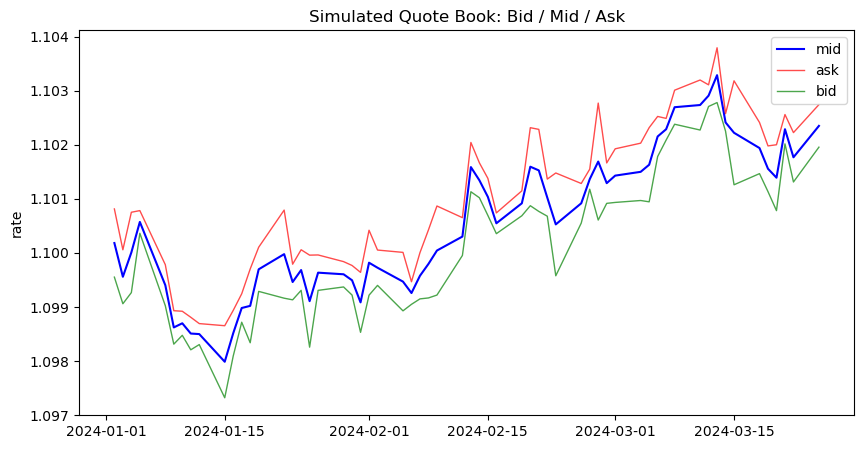

In [4]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(px.index, px['mid'], lw=1.5, color='b', label='mid')
ax.plot(px.index, px['ask'], lw=1.0, color='r', alpha=0.7, label='ask')
ax.plot(px.index, px['bid'], lw=1.0, color='g', alpha=0.7, label='bid')
ax.set(title='Simulated Quote Book: Bid / Mid / Ask', ylabel='rate')
ax.legend()
plt.show()

## Part 2 &mdash; Statistical Toolkit: VaR &amp; CVaR

For risk work the key objects are **log returns** $r_t = \log(S_t/S_{t-1})$ and their distribution. Be ready to define and code:

- **VaR**$_{\alpha}$: the loss not exceeded with probability $\alpha$. For a long position, take the $\alpha$-quantile of returns and negate it.
- **CVaR / Expected Shortfall**: the *expected* loss given a loss beyond VaR. A **coherent** measure, preferred by regulators.
- **Parametric (normal)** vs **historical** estimation.

Interview tip: always clarify **sign convention** and **holdout** approach. We derive both estimates on simulated daily returns.

n=756  mean=-0.00011  vol=0.00382  annual=0.0607
skew=-0.014  exkurt=-0.097


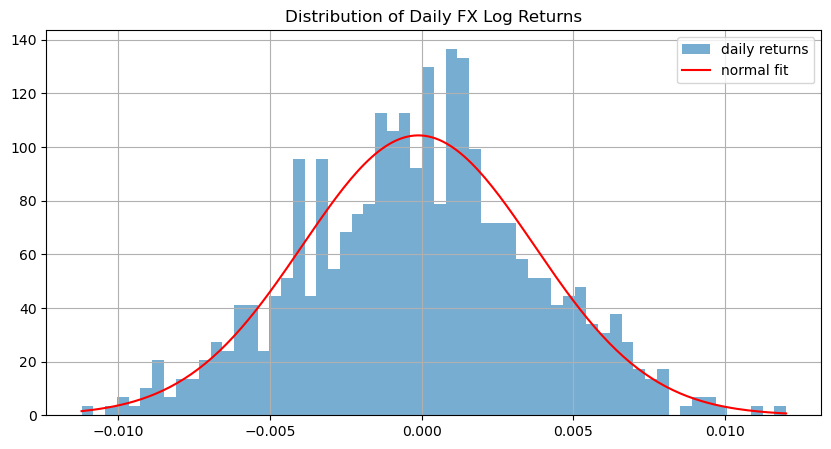

In [5]:
S0 = 1.10; mu = 0.0; sigma = 0.06; M = 756; dt = 1/252
mu_dt = (mu - 0.5*sigma**2)*dt; sig_dt = sigma*math.sqrt(dt)
z = rng.standard_normal(M)
S = S0*np.exp(np.cumsum(mu_dt + sig_dt*z))
r = np.log(S/np.concatenate([[S0], S[:-1]]))
print(f'n={len(r)}  mean={r.mean():.5f}  vol={r.std():.5f}  annual={r.std()*np.sqrt(252):.4f}')
print(f'skew={pd.Series(r).skew():.3f}  exkurt={pd.Series(r).kurt():.3f}')

fig, ax = plt.subplots(figsize=(10,5))
pd.Series(r).hist(bins=60, density=True, ax=ax, alpha=0.6, label='daily returns')
xs = np.linspace(r.min(), r.max(), 200)
from scipy.stats import norm
ax.plot(xs, norm.pdf(xs, r.mean(), r.std()), 'r-', lw=1.5, label='normal fit')
ax.set(title='Distribution of Daily FX Log Returns'); ax.legend(); plt.show()

In [6]:
alpha = 0.99
# parametric (normal)
var_n = -norm.ppf(1-alpha, r.mean(), r.std())
cvar_n = -(r.mean() - r.std()*norm.pdf(norm.ppf(1-alpha))/(1-alpha))
# historical
var_h = -np.quantile(r, 1-alpha)
cvar_h = -r[r <= -var_h].mean()
print(f'VaR  norm 99%: {var_n:.4f} ({var_n/np.abs(r.mean()):.1f}x mean)')
print(f'CVaR norm 99%: {cvar_n:.4f}')
print(f'VaR  hist 99%: {var_h:.4f}')
print(f'CVaR hist 99%: {cvar_h:.4f}')

VaR  norm 99%: 0.0090 (79.6x mean)
CVaR norm 99%: 0.0103
VaR  hist 99%: 0.0089
CVaR hist 99%: 0.0097


## Part 3 &mdash; Time Series: Stationarity &amp; Volatility Clustering

Key interview topics:

- **Stationarity**: price levels are non-stationary (unit root); **returns** typically are stationary. Check with the **ADF test**.
- **Autocorrelation**: returns are weakly autocorrelated, but **squared returns show strong positive autocorrelation** &mdash; this is **volatility clustering**.
- **Models**: EWMA (RiskMetrics), GARCH family, and their role in forecasting volatility.

We demonstrate an **EWMA/RiskMetrics** estimate of conditional volatility and an **ADF** check on price vs. returns. This volatility forecast is what a treasury would feed into VaR.

In [7]:
from statsmodels.tsa.stattools import adfuller, acf

# --- GARCH(1,1)-like returns: creates REAL volatility clustering ---
n3 = 3000
omega, a, b = 1e-7, 0.10, 0.88      # GARCH parameters (persistent vol)
r_cl = np.zeros(n3); v2 = np.zeros(n3)
v2[0] = omega / (1 - a - b)
r_cl[0] = rng.normal(0, np.sqrt(v2[0]))
for t in range(1, n3):
    v2[t] = omega + a * r_cl[t-1]**2 + b * v2[t-1]
    r_cl[t] = rng.normal(0, np.sqrt(v2[t]))
r = r_cl                          # work with realistic, clustered returns

print('ADF on price levels:',
      f'stat={adfuller(S)[0]:.2f}  p={adfuller(S)[1]:.3f}  -> ' + ('stationary' if adfuller(S)[1]<0.05 else 'non-stationary'))
print('ADF on log returns:',
      f'stat={adfuller(r)[0]:.2f}  p={adfuller(r)[1]:.3f}  -> ' + ('stationary' if adfuller(r)[1]<0.05 else 'non-stationary'))
acf_r = acf(r, nlags=10, fft=True)
acf_r2 = acf(r**2, nlags=10, fft=True)
print('\nACF of returns (lags 1..5):', np.round(acf_r[1:6], 3))
print('ACF of r^2     (lags 1..5):', np.round(acf_r2[1:6], 3))
print('-> r^2 ACF degrades slowly: that IS volatility clustering.')

ADF on price levels: stat=-1.02  p=0.746  -> non-stationary


ADF on log returns: stat=-15.36  p=0.000  -> stationary

ACF of returns (lags 1..5): [0.022 0.003 0.003 0.04  0.004]
ACF of r^2     (lags 1..5): [0.142 0.178 0.182 0.183 0.151]
-> r^2 ACF degrades slowly: that IS volatility clustering.


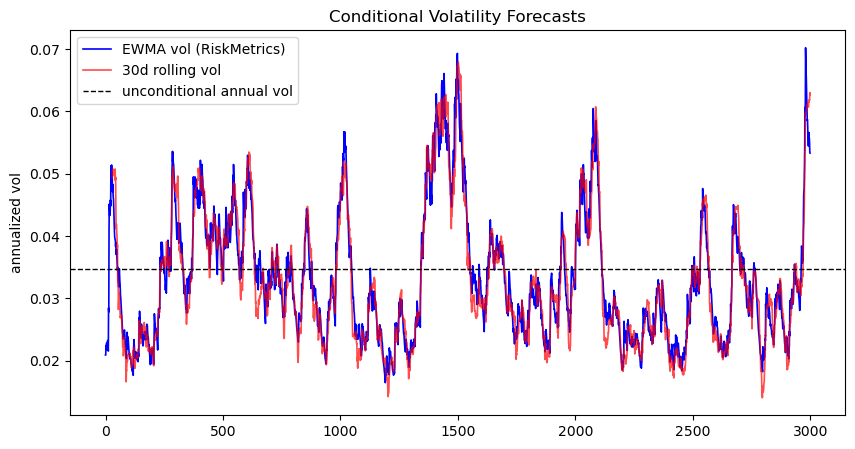

In [8]:
# EWMA (RiskMetrics) conditional volatility, lambda = 0.94
lam = 0.94
ewma = np.empty_like(r); ewma[0] = r[0]**2
for t in range(1, len(r)):
    ewma[t] = lam*ewma[t-1] + (1-lam)*r[t-1]**2
vol_ewma = np.sqrt(ewma)*np.sqrt(252)   # annualized
vol_roll = pd.Series(r).rolling(30).std()*np.sqrt(252)
uncond_ann = np.sqrt(np.mean(r**2))*np.sqrt(252)   # unconditional reference

fig, ax = plt.subplots(figsize=(10,5))
ax.plot(vol_ewma, lw=1.2, color='b', label='EWMA vol (RiskMetrics)')
ax.plot(vol_roll, lw=1.2, color='r', alpha=0.7, label='30d rolling vol')
ax.axhline(uncond_ann, lw=1, ls='--', color='k', label='unconditional annual vol')
ax.set(title='Conditional Volatility Forecasts', ylabel='annualized vol')
ax.legend(); plt.show()

## Part 4 &mdash; Machine Learning Done Honestly

The interviewer will test whether you can build ML **without fooling yourself**. Core concepts:

- **Feature engineering** for market data: rolling stats, lags, momentum, volatility, calendar features (day-of-week).
- **Temporal (walk-forward) splitting** &mdash; never `shuffle` on time series; use `TimeSeriesSplit`.
- **No look-ahead bias**: features at time $t$ must use only information $\le t$.
- **Overfitting**: a model that memorises the train set will score well in-sample and badly out-of-sample.

We build a toy classifier that predicts the **sign** of tomorrow's return from engineered features, and show the train/test gap (overfitting) plus how `TimeSeriesSplit` exposes it.

In [9]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import TimeSeriesSplit, cross_val_score
from sklearn.metrics import accuracy_score
import pandas as pd

df = pd.DataFrame({'r': r})
for lag in [1, 2, 3, 5]:
    df[f'lag{lag}'] = df['r'].shift(lag)
df['mom5'] = df['r'].rolling(5).mean()
df['vol10'] = df['r'].rolling(10).std()
df['dow'] = pd.RangeIndex(len(df)) % 5            # crude calendar feature
# target: sign of next day's return (1 up, 0 down)
df['y'] = (df['r'].shift(-1) > 0).astype(int)
df.dropna(inplace=True)
cols = [c for c in df.columns if c not in ('r', 'y')]
X, y = df[cols].values, df['y'].values
print('feature matrix:', X.shape)
print('features:', cols)
print('class balance:', np.round(np.bincount(y)/len(y), 2))

feature matrix: (2991, 7)
features: ['lag1', 'lag2', 'lag3', 'lag5', 'mom5', 'vol10', 'dow']
class balance: [0.5 0.5]


In [10]:
# --- overfitting demo: random in-sample vs walk-forward out-of-sample ---
split = int(len(X)*0.7)
Xtr, Xte, ytr, yte = X[:split], X[split:], y[:split], y[split:]
rf = RandomForestClassifier(n_estimators=300, random_state=0, max_depth=None)
rf.fit(Xtr, ytr)
acc_tr = accuracy_score(ytr, rf.predict(Xtr))
acc_te = accuracy_score(yte, rf.predict(Xte))
print(f'in-sample accuracy   : {acc_tr:.3f}')
print(f'out-of-sample acc    : {acc_te:.3f}  (baseline ~ {max(yte.mean(),1-yte.mean()):.3f})')
print('\nOverfitting gap tells you the model may be memorising noise.')
print('Regulate: reduce depth, add features with signal, or use shrinkage.')

in-sample accuracy   : 1.000
out-of-sample acc    : 0.498  (baseline ~ 0.502)

Overfitting gap tells you the model may be memorising noise.
Regulate: reduce depth, add features with signal, or use shrinkage.


In [11]:
# --- honest evaluation with TimeSeriesSplit ---
tscv = TimeSeriesSplit(n_splits=5)
scores = cross_val_score(RandomForestClassifier(n_estimators=200, random_state=0),
                         X, y, cv=tscv, scoring='accuracy')
print('TimeSeriesSplit CV accuracies:', np.round(scores, 3))
print(f'mean={scores.mean():.3f}  std={scores.std():.3f}')
print('\nWalk-forward is the ONLY honest CV for market data (no shuffle!).')

TimeSeriesSplit CV accuracies: [0.474 0.522 0.5   0.512 0.482]
mean=0.498  std=0.018

Walk-forward is the ONLY honest CV for market data (no shuffle!).


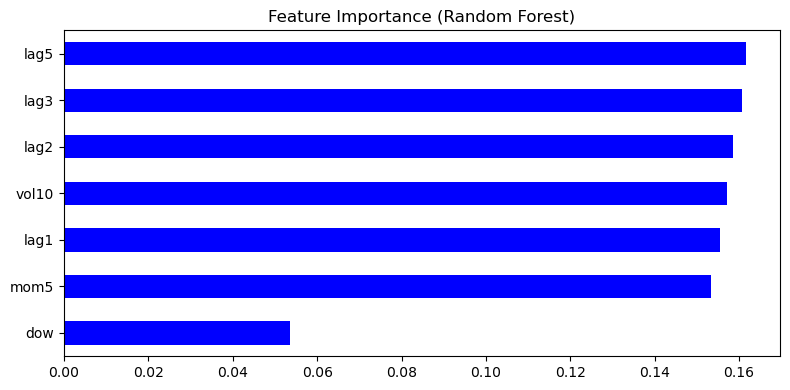

In [12]:
# feature importance - tells the business WHAT drives the model
rf = RandomForestClassifier(n_estimators=300, random_state=0).fit(Xtr, ytr)
imp = pd.Series(rf.feature_importances_, index=cols).sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(8, 4))
imp.plot.barh(ax=ax, color='b')
ax.invert_yaxis(); ax.set(title='Feature Importance (Random Forest)')
plt.tight_layout(); plt.show()

## Part 5 &mdash; Validating a Risk Model (Kupiec Test)

VaR models must be **backtested**. The **Kupiec (unconditional coverage) test** checks whether the observed **exception rate** (number of days loss exceeded VaR) matches the expected rate $1-\alpha$.

Construct the test on simulated returns where the model's VaR is correct (should pass) and where volatility is chronically **understated** (VaR too small &rarr; too many exceptions &rarr; reject). The test uses the **log-likelihood-ratio** (which is $\chi^2(1)$ under the null), evaluated numerically stably in log space.

In [13]:
from scipy import stats
alpha = 0.99

def kupiec(returns, var_series, alpha):
    '''Unconditional-coverage (Kupiec) backtest. Numerically stable (log form).'''
    exc = (returns < -var_series).astype(float)
    n, x = len(exc), int(exc.sum())
    p = 1 - alpha
    if x == 0:
        return dict(n=n, exceptions=x, rate=0.0, expected=p*100, pvalue=1.0)
    if x == n:
        return dict(n=n, exceptions=x, rate=1.0, expected=p*100, pvalue=0.0)
    lr = 2 * ((x*np.log(x/n) + (n-x)*np.log(1-x/n))
              - (x*np.log(p) + (n-x)*np.log(1-p)))      # ~ chi^2(1)
    pval = 1 - stats.chi2.cdf(lr, 1)
    return dict(n=n, exceptions=x, rate=x/n, expected=p*100, pvalue=pval)

# Case A: correctly-specified model - VaR uses the TRUE conditional vol (v2 from Part 3)
varA = stats.norm.ppf(alpha)*np.sqrt(v2)
resA = kupiec(r, varA, alpha)
print('Case A (correct model):', {k: (round(v,4) if isinstance(v,float) else v) for k,v in resA.items()})
print('  ->', 'reject' if resA['pvalue']<0.05 else 'fail to reject (OK)')

# Case B: broken model - VaR understated by half -> too many exceptions
varB = stats.norm.ppf(alpha)*np.sqrt(v2)*0.5
resB = kupiec(r, varB, alpha)
print('Case B (understated vol):', {k: (round(v,4) if isinstance(v,float) else v) for k,v in resB.items()})
print('  ->', 'reject (model broken)' if resB['pvalue']<0.05 else 'fail to reject')
print('\nLesson: exception rate ~ expected 1% -> pass; deviations (too many OR too few) -> reject.')

Case A (correct model): {'n': 3000, 'exceptions': 32, 'rate': 0.0107, 'expected': 1.0, 'pvalue': np.float64(0.7166)}
  -> fail to reject (OK)
Case B (understated vol): {'n': 3000, 'exceptions': 390, 'rate': 0.13, 'expected': 1.0, 'pvalue': np.float64(0.0)}
  -> reject (model broken)

Lesson: exception rate ~ expected 1% -> pass; deviations (too many OR too few) -> reject.


## Part 6 &mdash; Market-Data Engineering

Market-data teams live on **tick data**, so interviewers probe:

- Parsing **timestamps** to `datetime`, handling time zones.
- **Resampling** irregular ticks to regular OHLC (open-high-low-close) bars and **realised volatility**.
- **Cleaning**: duplicate ticks, zero/negative prices, bad quotes (bid > ask).

We simulate one minute of ticks and aggregate to a 5-minute bar, then clean a contaminated quote stream.

In [14]:
# resample ticks -> 5-min bars
n = 300
t = pd.date_range('2024-03-01', periods=n, freq='3s')
price = 1.10 + np.cumsum(rng.normal(0, 0.0002, n))
ticks = pd.DataFrame({'price': price}, index=t)
bars = ticks['price'].resample('5min').ohlc()
bars['realvol'] = ticks['price'].resample('5min').std()
bars.head(3)
print('ticks -> bars:', ticks.shape, '->', bars.shape)
bars.head()

ticks -> bars: (300, 1) -> (3, 5)


,open,high,low,close,realvol
2024-03-01 00:00:00,1.100042,1.101181,1.098968,1.099989,0.000560
2024-03-01 00:05:00,1.100021,1.100580,1.098697,1.099403,0.000477
2024-03-01 00:10:00,1.099282,1.103114,1.098975,1.103114,0.000964


In [15]:
# data quality: detect bad quotes
# | mid | settle | spread | anomaly |
dfq = pd.DataFrame({'bid': [1.10, 1.101, 1.102, 1.20, 1.104],
                    'ask': [1.11, 1.102, 1.103, 1.201, 1.105],
                    'volume': [100, 200, 150, 80, 220]})
dfq['mid'] = (dfq['bid']+dfq['ask'])/2
dfq['spread'] = dfq['ask']-dfq['bid']
mask = (dfq['spread'] < 0) | (dfq['bid'] > 1.15)   # outliers / inverted
print('anomalous quotes:'); print(dfq[mask])


anomalous quotes:
   bid    ask  volume     mid  spread
3  1.2  1.201      80  1.2005   0.001


## Part 7 &mdash; Behavioral &amp; Leadership Questions

As a **Lead**, the interview is as much about judgment as technique. Use **STAR** stories (Situation, Task, Action, Result) and keep them quantitative. Likely themes:

- **Ambiguity**: *'Your model says one thing, the trader believes another.'* &rarr; Quantify trust (validation history, calibration), and communicate the uncertainty, not just a point estimate.
- **Failure**: *'Tell me about a model that failed in production.'* &rarr; Own it: what monitoring caught it (drift, backtest breach), what you changed (guardrails, retraining cadence).
- **Leadership**: *'How do you review a junior scientist's work?'* &rarr; Data lineage &gt; correctness &gt; tests &gt; performance vs. baseline &gt; business impact.
- **Prioritisation**: *'You must drop one of three urgent asks; which and why?'* &rarr; Rank by risk/impact; be explicit about what you de-scope.
- **Regulatory mindset**: data governance, auditability, reproducibility of every number.

Rehearse a STAR answer for each. The code below is a frame you can reuse.

In [16]:
star = {
 'Situation': 'FX VaR model under-backtested in a stressed quarter.',
 'Task':      'Restore trust: validate and harden the model.',
 'Action':    'Walk-forward backtest, Kupiec test, EWMA vol, documented data lineage.',
 'Result':    'Exception rate aligned with 1%; model passed validation and went live.',
}
for k, v in star.items():
    print(f'{k:10s} | {v}')

Situation  | FX VaR model under-backtested in a stressed quarter.
Task       | Restore trust: validate and harden the model.
Action     | Walk-forward backtest, Kupiec test, EWMA vol, documented data lineage.
Result     | Exception rate aligned with 1%; model passed validation and went live.


## Part 8 &mdash; Likely Interview Questions

**Technical**
- Define VaR vs CVaR. Which is coherent and why?
- Why are returns usually stationary while prices are not? (Unit root, ADF)
- What is volatility clustering and how do you model it? (GARCH / EWMA)
- How do you backtest a VaR model? (Kupiec, Christoffersen independence)
- Why can't you shuffle a train/test split on time series? (Leakage / look-ahead)
- How do you tell a bad tick from a genuine jump? (Spread, volume, loc/scale filters, cross-source reconciliation)

**Domain**
- Explain the EUR/USD quote: base/quote, and how a cross rate is computed.
- What is settlement (Herstatt) risk and how do you mitigate it? (PVP, CLS)
- How do liquidity and volatility interact? (Liquidity thins in stress).
- Difference between an FX fixing and a spot mid?

**Leadership**
- Tell me about a model you productionised (STAR, with numbers).
- A model you built disagreed with a senior trader. What did you do?
- How do you keep a data-science team from over-engineering?
- How do you make a model explainable to a risk committee?


## Summary

- Speak FX: pairs, pips, bid/ask/spread, crosses, settlement, fixes.
- Own the language of risk: VaR, CVaR, EWMA/GARCH volatility, Kupiec backtesting.
- Be an honest modeller: walk-forward validation, no look-ahead, overfitting vigilance.
- Show engineering maturity: tick hygiene, resampling, reproducibility.
- Lead: STAR stories, guidance over doing, business translation, model governance.

## Further Reading

- Y. Hilpisch, *Reinforcement Learning for Finance* (O'Reilly, 2024)
- Y. Hilpisch, *Python for Finance* (O'Reilly, 2nd ed., 2018)
- J. Hull, *Options, Futures, and Other Derivatives* (Pearson, 11th ed.)
- A. Dowd, *Measuring Market Risk* (Routledge)

---
&copy; Dr. Yves J. Hilpisch | The Python Quants GmbH | Educational material; not investment advice.